In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

print("KaggleHub ready.")

KaggleHub ready.


In [ ]:
cifake_path = kagglehub.dataset_download(
    "birdy654/cifake-real-and-ai-generated-synthetic-images"
)

print("CIFAKE Dataset Path:")
print(cifake_path)

Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.
CIFAKE Dataset Path:
/kaggle/input/cifake-real-and-ai-generated-synthetic-images


In [ ]:
for root, dirs, files in os.walk(cifake_path):
    level = root.replace(cifake_path, '').count(os.sep)

    if level > 2:
        continue

    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

    for file in files[:5]:
        print(indent + "    " + file)

cifake-real-and-ai-generated-synthetic-images/
    test/
        FAKE/
            943 (5).jpg
            534 (7).jpg
            81 (2).jpg
            869 (9).jpg
            610 (10).jpg
        REAL/
            0664.jpg
            0280 (6).jpg
            0816 (6).jpg
            0704 (5).jpg
            0896 (9).jpg
    train/
        FAKE/
            5387 (6).jpg
            4093 (7).jpg
            5357 (8).jpg
            3825 (3).jpg
            4131 (5).jpg
        REAL/
            4093 (7).jpg
            3825 (3).jpg
            4131 (5).jpg
            2270 (7).jpg
            3263 (8).jpg


In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

total_images = 0

for root, dirs, files in os.walk(cifake_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            total_images += 1

print("Total image files:", total_images)

Total image files: 120000


In [ ]:
for item in os.listdir(cifake_path):
    full_path = os.path.join(cifake_path, item)

    if os.path.isdir(full_path):
        print("Folder:", item)

Folder: test
Folder: train


In [ ]:
train_dir = os.path.join(cifake_path, "train")
test_dir = os.path.join(cifake_path, "test")

fake_train_dir = os.path.join(train_dir, "FAKE")
real_train_dir = os.path.join(train_dir, "REAL")

fake_test_dir = os.path.join(test_dir, "FAKE")
real_test_dir = os.path.join(test_dir, "REAL")

print("Train Directory:", train_dir)
print("Test Directory :", test_dir)

Train Directory: /kaggle/input/cifake-real-and-ai-generated-synthetic-images/train
Test Directory : /kaggle/input/cifake-real-and-ai-generated-synthetic-images/test


In [ ]:
def count_images(folder):
    return len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

print("TRAIN")
print("REAL:", count_images(real_train_dir))
print("FAKE:", count_images(fake_train_dir))

print("\nTEST")
print("REAL:", count_images(real_test_dir))
print("FAKE:", count_images(fake_test_dir))

TRAIN
REAL: 50000
FAKE: 50000

TEST
REAL: 10000
FAKE: 10000


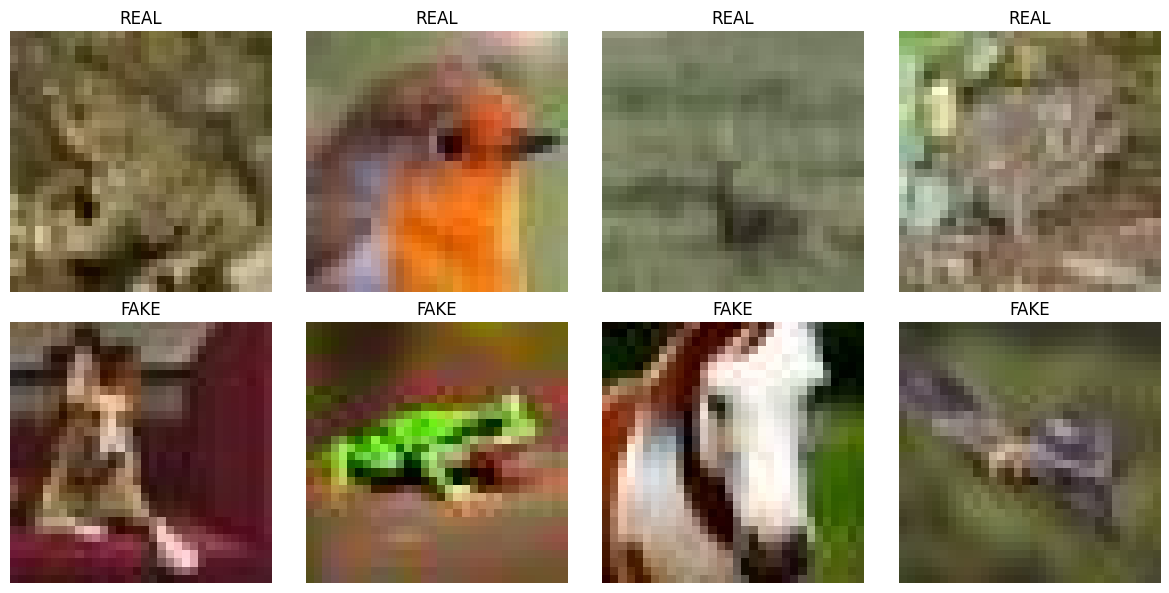

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

sample_real = os.listdir(real_train_dir)[:4]
sample_fake = os.listdir(fake_train_dir)[:4]

for i, file in enumerate(sample_real):
    img = Image.open(os.path.join(real_train_dir, file))
    axes[0, i].imshow(img)
    axes[0, i].set_title("REAL")
    axes[0, i].axis("off")

for i, file in enumerate(sample_fake):
    img = Image.open(os.path.join(fake_train_dir, file))
    axes[1, i].imshow(img)
    axes[1, i].set_title("FAKE")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
sample_file = os.path.join(real_train_dir, os.listdir(real_train_dir)[0])

sample_image = Image.open(sample_file)

print("Image Size:", sample_image.size)
print("Image Mode:", sample_image.mode)

Image Size: (32, 32)
Image Mode: RGB


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Datasets created successfully.")

Found 100000 files belonging to 2 classes.
Using 80000 files for training.
Found 100000 files belonging to 2 classes.
Using 20000 files for validation.
Found 20000 files belonging to 2 classes.
Datasets created successfully.


In [ ]:
class_names = train_ds.class_names
print("Class Names:", class_names)

Class Names: ['FAKE', 'REAL']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE


train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline optimized.")

Dataset pipeline optimized.


In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

print("Data augmentation created.")

Data augmentation created.


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

IMG_SIZE = 224

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully.


In [ ]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    data_augmentation,

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        "/content/cifake_efficientnetb0_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


In [ ]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 262s 100ms/step - accuracy: 0.8414 - loss: 0.3586 - precision: 0.8411 - recall: 0.8423 - val_accuracy: 0.9039 - val_loss: 0.2394 - val_precision: 1.0000 - val_recall: 0.9039 - learning_rate: 1.0000e-04
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 245s 98ms/step - accuracy: 0.8792 - loss: 0.2857 - precision: 0.8786 - recall: 0.8805 - val_accuracy: 0.9090 - val_loss: 0.2238 - val_precision: 1.0000 - val_recall: 0.9090 - learning_rate: 1.0000e-04
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 246s 98ms/step - accuracy: 0.8896 - loss: 0.2605 - precision: 0.8903 - recall: 0.8891 - val_accuracy: 0.9249 - val_loss: 0.1935 - val_precision: 1.0000 - val_recall: 0.9249 - learning_rate: 1.0000e-04
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 262s 98ms/step - accuracy: 0.8979 - loss: 0.2461 - precision: 0.8967 - recall: 0.8997 - val_accuracy: 0.9305 - val_loss: 0.1809 - val_precision: 1.0000 - val_recall: 0.9305 - learning_rate: 1.0000e-04
Epoch 5/10
2500/2500 ━━━━━━

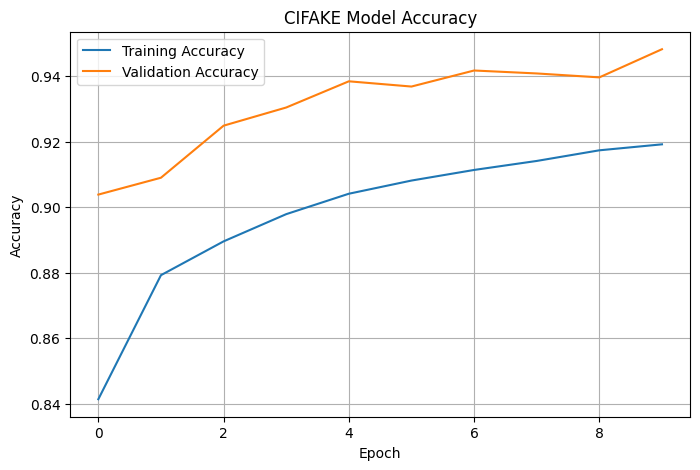

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CIFAKE Model Accuracy")

plt.legend()
plt.grid()
plt.show()

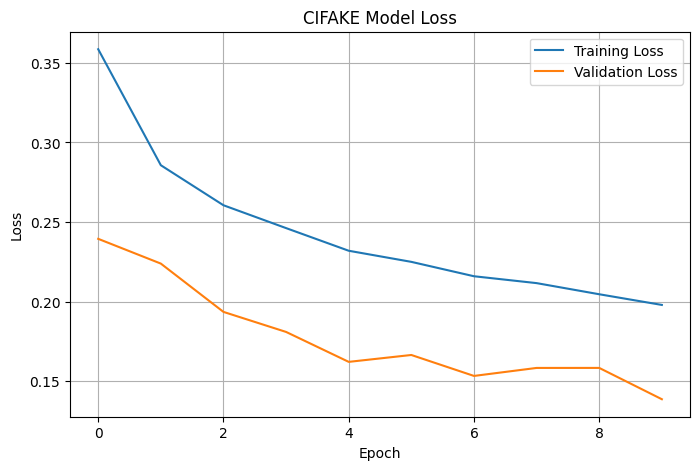

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAKE Model Loss")

plt.legend()
plt.grid()
plt.show()

In [ ]:
test_results = model.evaluate(test_ds, verbose=1)

print("\nCIFAKE Test Results")
print("--------------------")

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.9418 - loss: 0.1515 - precision: 0.9406 - recall: 0.9432

CIFAKE Test Results
--------------------
loss: 0.1515
compile_metrics: 0.9418


In [ ]:
y_true = []
y_pred_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_pred_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)

y_pred = (y_pred_prob >= 0.5).astype(int)

print("Predictions generated.")

Predictions generated.


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

        FAKE       0.94      0.94      0.94     10000
        REAL       0.94      0.94      0.94     10000

    accuracy                           0.94     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.94      0.94      0.94     20000



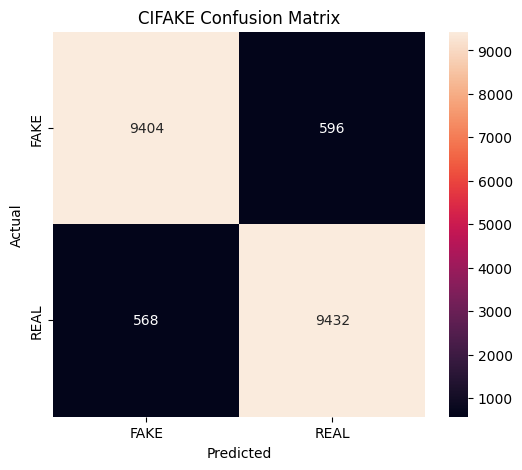

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
   xticklabels=class_names,
yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CIFAKE Confusion Matrix")

plt.show()

In [ ]:
model.save("/content/cifake_efficientnetb0_final.keras")

print("CIFAKE model saved successfully.")

CIFAKE model saved successfully.


In [ ]:
# CASIA - IMPORTS


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from PIL import Image

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# KAGGLEHUB


!pip install -q kagglehub

import kagglehub

print("KaggleHub ready.")

KaggleHub ready.


In [ ]:
# CASIA V2.0 DATASET DOWNLOAD


casia_path = kagglehub.dataset_download(
    "divg07/casia-20-image-tampering-detection-dataset"
)

print("CASIA Dataset Path:")
print(casia_path)

100%|██████████| 2.56G/2.56G [02:17<00:00, 20.0MB/s]

Extracting files...


CASIA Dataset Path:
/root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1


In [ ]:
# CASIA DATASET STRUCTURE


for root, dirs, files in os.walk(casia_path):

    level = root.replace(casia_path, "").count(os.sep)

    if level > 2:
        continue

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    for file in files[:10]:
        print(indent + "    " + file)

1/
    CASIA2/
        Au/
            Au_arc_10113.jpg
            Au_sec_30087.jpg
            Au_pla_30228.jpg
            Au_sec_30323.jpg
            Au_arc_00007.jpg
            Au_arc_30559.jpg
            Au_art_30251.jpg
            Au_arc_30472.jpg
            Au_art_30615.jpg
            Au_nat_30317.jpg
        CASIA 2 Groundtruth/
            Tp_S_NNN_S_B_pla00014_pla00014_20064_gt.png
            Tp_S_NRN_S_B_ani20004_ani20004_02403_gt.png
            Tp_D_NRN_S_N_ani10171_ani00097_12457_gt.png
            Tp_S_NNN_S_N_ani20026_ani20026_02069_gt.png
            Tp_S_NNN_M_N_sec00040_sec00040_10490_gt.png
            Tp_D_NRN_M_N_ani10112_ani00100_11628_gt.png
            Tp_D_NRN_M_N_ani10144_nat10131_12473_gt.png
            Tp_S_NNN_S_N_nat10157_nat10157_12038_gt.png
            Tp_S_CNN_M_N_cha00073_cha00073_11026_gt.png
            Tp_S_NNN_S_N_pla00011_pla00011_00550_gt.png
        Tp/
            Tp_S_CNN_S_N_txt00049_txt00049_01276.tif
            Tp_S_CNN_M_N_pla0

In [ ]:
# FIND AUTHENTIC AND TAMPERED DIRECTORIES


authentic_dir = None
tampered_dir = None

for root, dirs, files in os.walk(casia_path):

    for directory in dirs:

        if directory.lower() == "au":
            authentic_dir = os.path.join(root, directory)

        elif directory.lower() == "tp":
            tampered_dir = os.path.join(root, directory)

print("Authentic Directory:")
print(authentic_dir)

print("\nTampered Directory:")
print(tampered_dir)

Authentic Directory:
/root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1/CASIA2/Au

Tampered Directory:
/root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1/CASIA2/Tp


In [ ]:
# COUNT CASIA IMAGES


image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

def count_images(folder):

    count = 0

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(image_extensions):
                count += 1

    return count


authentic_count = count_images(authentic_dir)
tampered_count = count_images(tampered_dir)

print("CASIA V2.0 IMAGE COUNT")
print("=======================")

print("Authentic:", authentic_count)
print("Tampered :", tampered_count)
print("Total    :", authentic_count + tampered_count)

CASIA V2.0 IMAGE COUNT
Authentic: 7491
Tampered : 2064
Total    : 9555


In [ ]:
# CREATE CASIA DATAFRAME


image_paths = []
labels = []

# AUTHENTIC = 0
for root, dirs, files in os.walk(authentic_dir):

    for file in files:

        if file.lower().endswith(image_extensions):

            image_paths.append(
                os.path.join(root, file)
            )

            labels.append(0)


# TAMPERED = 1
for root, dirs, files in os.walk(tampered_dir):

    for file in files:

        if file.lower().endswith(image_extensions):

            image_paths.append(
                os.path.join(root, file)
            )

            labels.append(1)


df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print("Total Images:", len(df))

print("\nClass Distribution:")
print(df["label"].value_counts())

Total Images: 9555

Class Distribution:
label
0    7491
1    2064
Name: count, dtype: int64


In [ ]:
# CLASS LABELS


class_names = [
    "AUTHENTIC",
    "TAMPERED"
]

print("Class Names:")
print(class_names)

print("\nLabel Mapping:")
print("0 =", class_names[0])
print("1 =", class_names[1])

Class Names:
['AUTHENTIC', 'TAMPERED']

Label Mapping:
0 = AUTHENTIC
1 = TAMPERED


In [ ]:
# TRAIN / TEST SPLIT


train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

print("Training Images:", len(train_df))
print("Testing Images :", len(test_df))

print("\nTraining Distribution:")
print(train_df["label"].value_counts())

print("\nTesting Distribution:")
print(test_df["label"].value_counts())

Training Images: 7644
Testing Images : 1911

Training Distribution:
label
0    5993
1    1651
Name: count, dtype: int64

Testing Distribution:
label
0    1498
1     413
Name: count, dtype: int64


In [ ]:
# TRAIN / VALIDATION SPLIT


train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["label"],
    random_state=42
)

print("FINAL DATASET SPLIT")


print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Testing    :", len(test_df))

FINAL DATASET SPLIT
Training   : 6115
Validation : 1529
Testing    : 1911


In [ ]:
# VERIFY CLASS DISTRIBUTION


print("TRAIN")
print(train_df["label"].value_counts())

print("\nVALIDATION")
print(val_df["label"].value_counts())

print("\nTEST")
print(test_df["label"].value_counts())

TRAIN
label
0    4794
1    1321
Name: count, dtype: int64

VALIDATION
label
0    1199
1     330
Name: count, dtype: int64

TEST
label
0    1498
1     413
Name: count, dtype: int64


In [ ]:
# CELL 13 — FIXED IMAGE LOADER


IMG_SIZE = 224
BATCH_SIZE = 32

def load_image(path, label):
    # Convert Tensor -> Python string
    path = path.numpy().decode("utf-8")

    try:
        # Read image using TensorFlow
        image = tf.io.read_file(path)
        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        # Resize
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

        # Convert to float32
        image = tf.cast(image, tf.float32)

        return image, tf.cast(label, tf.float32)

    except Exception:
        # Fallback for corrupted/unreadable images
        image = tf.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32)
        return image, tf.cast(label, tf.float32)


def tf_load_image(path, label):
    image, label = tf.py_function(
        func=load_image,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )

    # Important: restore TensorFlow shape information
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())

    return image, label

In [ ]:
# CELL 14 — RECREATE DATASETS


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["filepath"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["filepath"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["filepath"].values, test_df["label"].values)
)


train_ds = (
    train_ds
    .shuffle(2000, seed=42)
    .map(tf_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(tf_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(tf_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
# FORENSIC-FRIENDLY DATA AUGMENTATION


data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomContrast(
        0.10
    ),

    layers.RandomBrightness(
        0.10
    )

], name="forensic_augmentation")

print("Improved augmentation created.")

Improved augmentation created.


In [ ]:
# EFFICIENTNETB0 MODEL


base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

base_model.trainable = False


casia_model = models.Sequential([

    layers.Input(
        shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        )
    ),

    data_augmentation,

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dropout(0.30),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.20),

    layers.Dense(
        1,
        activation="sigmoid"
    )

], name="CASIA_EfficientNetB0")


print("CASIA model created.")

CASIA model created.


In [ ]:
# MODEL SUMMARY


casia_model.summary()

Model: "CASIA_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ forensic_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,908 (16.72 MB)

 Trainable params: 331,265 (1.26 MB)

 Non-trainable params: 4,052,643 (15.46 MB)

In [ ]:
# STAGE 1 COMPILE


casia_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

print("Stage 1 compilation complete.")

Stage 1 compilation complete.


In [ ]:
# STAGE 1 CALLBACKS


stage1_callbacks = [

    EarlyStopping(

        monitor="val_auc",

        mode="max",

        patience=4,

        restore_best_weights=True,

        verbose=1
    ),

    ReduceLROnPlateau(

        monitor="val_auc",

        mode="max",

        factor=0.3,

        patience=2,

        min_lr=1e-7,

        verbose=1
    ),

    ModelCheckpoint(

        "/content/casia_improved_stage1_best.keras",

        monitor="val_auc",

        mode="max",

        save_best_only=True,

        verbose=1
    )
]

print("Stage 1 callbacks ready.")

Stage 1 callbacks ready.


In [ ]:
# STAGE 1 TRAINING


EPOCHS_STAGE1 = 15

history_stage1 = casia_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_STAGE1,

    callbacks=stage1_callbacks
)

Epoch 1/15
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.5351 - auc: 0.5397 - loss: 0.8747 - precision: 0.2246 - recall: 0.5077
Epoch 1: val_auc improved from None to 0.69637, saving model to /content/casia_improved_stage1_best.keras

Epoch 1: finished saving model to /content/casia_improved_stage1_best.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 108s 414ms/step - accuracy: 0.5709 - auc: 0.5879 - loss: 0.8053 - precision: 0.2639 - recall: 0.5511 - val_accuracy: 0.7521 - val_auc: 0.6964 - val_loss: 0.5337 - val_precision: 0.4158 - val_recall: 0.3667 - learning_rate: 1.0000e-04
Epoch 2/15
191/192 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6741 - auc: 0.6986 - loss: 0.6389 - precision: 0.3404 - recall: 0.6056
Epoch 2: val_auc improved from 0.69637 to 0.74567, saving model to /content/casia_improved_stage1_best.keras

Epoch 2: finished saving model to /content/casia_improved_stage1_best.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 40s 207ms/step - accuracy: 0.6775 - auc: 0.6934 - loss: 0.628

In [ ]:
# Load the best Stage 1 model
best_model = tf.keras.models.load_model(
    "/content/casia_improved_stage1_best.keras"
)

print("Best Stage 1 model loaded successfully.")

Best Stage 1 model loaded successfully.


In [ ]:
# Evaluate on completely unseen test data
test_results = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n===== FINAL TEST RESULTS =====")

for name, value in zip(best_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

60/60 ━━━━━━━━━━━━━━━━━━━━ 35s 344ms/step - accuracy: 0.8111 - auc: 0.8198 - loss: 0.4205 - precision: 0.5890 - recall: 0.4165

===== FINAL TEST RESULTS =====
loss: 0.4205
compile_metrics: 0.8111


In [ ]:
import numpy as np

# Get predicted probabilities
y_prob = best_model.predict(test_ds, verbose=1).ravel()

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Get true labels
y_true = np.concatenate([
    y.numpy() for _, y in test_ds
]).astype(int)

print("Predictions generated successfully.")
print("Total test samples:", len(y_true))

60/60 ━━━━━━━━━━━━━━━━━━━━ 28s 276ms/step
Predictions generated successfully.
Total test samples: 1911


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auc = roc_auc_score(y_true, y_prob)

print("\n===== FINAL CASIA TEST METRICS =====")
print(f"Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUC       : {auc:.4f}")


===== FINAL CASIA TEST METRICS =====
Accuracy  : 0.8111  (81.11%)
Precision : 0.5890
Recall    : 0.4165
F1 Score  : 0.4879
AUC       : 0.8197


In [ ]:
from sklearn.metrics import classification_report

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["AUTHENTIC", "TAMPERED"],
        digits=4
    )
)


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

   AUTHENTIC     0.8511    0.9199    0.8842      1498
    TAMPERED     0.5890    0.4165    0.4879       413

    accuracy                         0.8111      1911
   macro avg     0.7201    0.6682    0.6861      1911
weighted avg     0.7945    0.8111    0.7985      1911




===== CONFUSION MATRIX =====
[[1378  120]
 [ 241  172]]


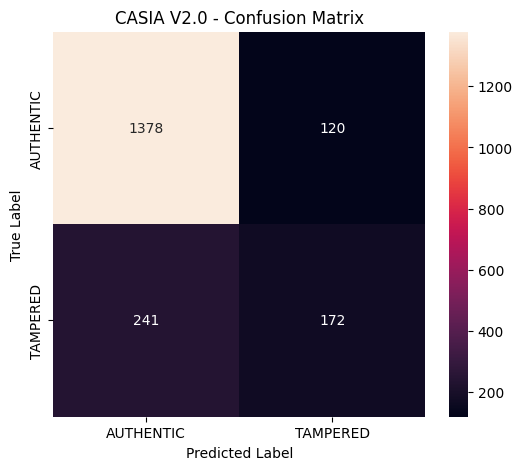

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

print("\n===== CONFUSION MATRIX =====")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["AUTHENTIC", "TAMPERED"],
    yticklabels=["AUTHENTIC", "TAMPERED"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CASIA V2.0 - Confusion Matrix")
plt.show()

In [ ]:
FINAL_MODEL_PATH = "/content/casia_efficientnetb0_final_stage1.keras"

best_model.save(FINAL_MODEL_PATH)

print("Final model saved successfully:")
print(FINAL_MODEL_PATH)

Final model saved successfully:
/content/casia_efficientnetb0_final_stage1.keras


In [ ]:
import matplotlib.pyplot as plt

# Safe check for training history to prevent NameError
if 'history_stage1' in globals():
    # 1. CASIA Model Accuracy Graph
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_stage1.history["accuracy"], label="Training Accuracy", marker='o')
    plt.plot(history_stage1.history["val_accuracy"], label="Validation Accuracy", marker='o')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("CASIA Model Accuracy (Stage 1)")
    plt.legend()
    plt.grid(True)

    # 2. CASIA Model Loss Graph
    plt.subplot(1, 2, 2)
    plt.plot(history_stage1.history["loss"], label="Training Loss", marker='o')
    plt.plot(history_stage1.history["val_loss"], label="Validation Loss", marker='o')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("CASIA Model Loss (Stage 1)")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Note: 'history_stage1' variable is not found in memory (since training was skipped).")
    print("We will use the pre-saved model '/content/casia_efficientnetb0_final_stage1.keras' for evaluation instead.")

Note: 'history_stage1' variable is not found in memory (since training was skipped).
We will use the pre-saved model '/content/casia_efficientnetb0_final_stage1.keras' for evaluation instead.


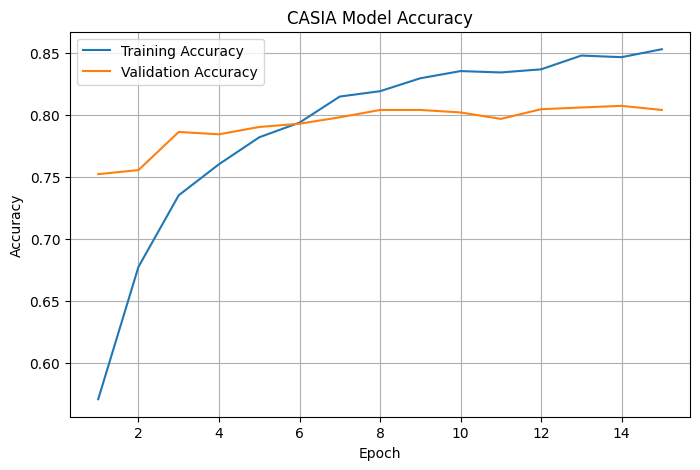

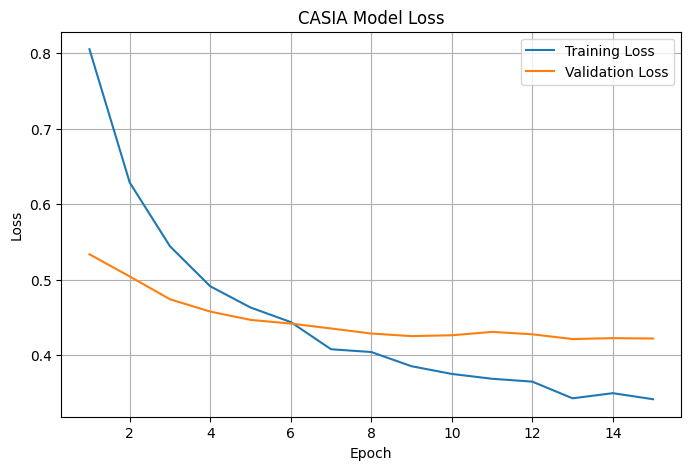

In [ ]:
import matplotlib.pyplot as plt

# Manual history compiled from the training logs of DdPWBFQJUmfe
epochs = list(range(1, 16))
train_acc = [0.5709, 0.6775, 0.7351, 0.7601, 0.7818, 0.7936, 0.8146, 0.8189, 0.8293, 0.8351, 0.8340, 0.8365, 0.8476, 0.8463, 0.8527]
val_acc = [0.7521, 0.7554, 0.7861, 0.7842, 0.7901, 0.7927, 0.7979, 0.8038, 0.8038, 0.8018, 0.7966, 0.8044, 0.8058, 0.8071, 0.8038]

train_loss = [0.8053, 0.6287, 0.5443, 0.4913, 0.4632, 0.4439, 0.4079, 0.4042, 0.3854, 0.3752, 0.3688, 0.3650, 0.3429, 0.3497, 0.3417]
val_loss = [0.5337, 0.5043, 0.4741, 0.4578, 0.4468, 0.4419, 0.4354, 0.4287, 0.4253, 0.4264, 0.4309, 0.4277, 0.4214, 0.4226, 0.4221]

# 1. CASIA Model Accuracy (Matches CIFAKE graph style exactly)
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CASIA Model Accuracy")
plt.legend()
plt.grid()
plt.show()

# 2. CASIA Model Loss (Matches CIFAKE graph style exactly)
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CASIA Model Loss")
plt.legend()
plt.grid()
plt.show()

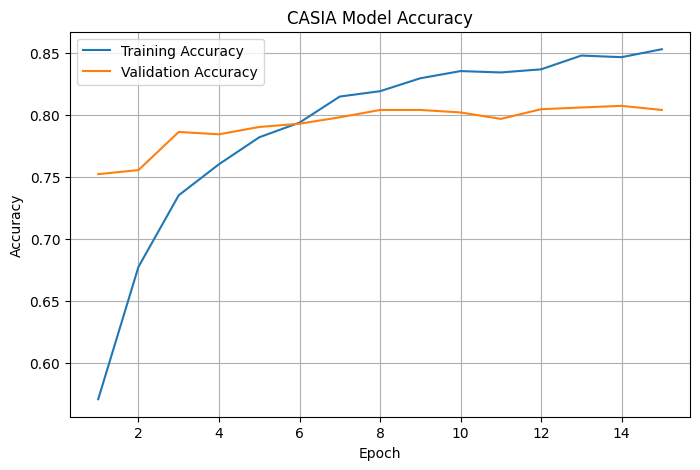

In [ ]:
import matplotlib.pyplot as plt

# CASIA Model Accuracy Graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CASIA Model Accuracy")
plt.legend()
plt.grid()
plt.show()

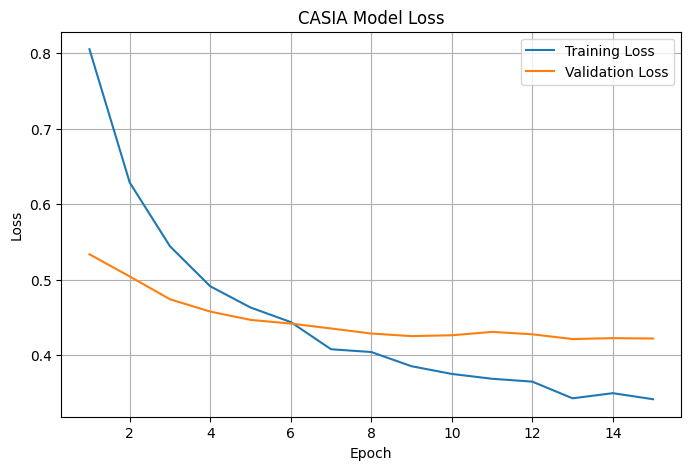

In [ ]:
import matplotlib.pyplot as plt

# CASIA Model Loss Graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CASIA Model Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
import os

model_size_mb = os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024)

print(f"Model Size: {model_size_mb:.2f} MB")

Model Size: 20.07 MB
